# BTC states and five-day first-passage probabilities

## Overview

This is the main research notebook, extended one module at a time. It currently
constructs BTC states from the permitted 2020–2023 development data, estimates a
transition matrix in the fixed 2023 window, and calculates its implied five-day
first-passage probabilities. It also constructs realized five-day outcome
labels and demonstrates their maturity filter. The matrix calculations are
**descriptive and in-sample**.
Section 7 checks five-step CK consistency with a fitted-null simulation.
The residence-time diagnostic, joint testing decision, and predictive
performance evaluation remain pending. Section 8 contains outcome-label
preparation for the later rolling-forecast workflow.

## Context and methods

State 0 is a negative daily shock; states 1 and 2 are the non-risk starting states.
The fixed 2023 window is specified in the draft protocol. Features are calculated
using the earlier development history before selecting that window.

### Key assumptions

- First-passage calculations assume a homogeneous first-order transition matrix.
  Counting transitions alone does not establish that assumption. CK is one
  necessary-implication diagnostic, not proof of the full assumption.
- The matrix below uses raw row frequencies without smoothing. The draft's
  smoothed rolling forecasts will be implemented separately.
- No prices dated 2024 or later are read. The protocol is still DRAFT.

## Setup

Install `requirements-notebook.txt` and run from the project root or its
`notebooks` directory. Core functions are defined directly in the relevant sections below, followed
by their use on real data. Artificial examples and independent formula checks
live in `tests/test_markov.py`; the tests load these same notebook definitions.


In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "AGENTS.md").exists() else Path.cwd().parent

csv_path = ROOT / "data/development/BTCUSDT_1d_2020-01_2023-12.csv"
window_start, window_end = "2023-01-01", "2023-12-31"
horizon = 5


## 1. Read development closing prices

Source: Binance public spot daily candles, BTCUSDT, UTC calendar days. The unit of `close` is USDT/BTC.

Read dates first to confirm that the file covers the permitted, continuous 2020–2023 calendar before reading closing prices. Only the fixed development file is used; no other directories are scanned.

The helper below checks calendar integrity; the following cell loads the permitted data.


In [2]:
def _validate_daily_index(index: pd.Index) -> None:
    """Require consecutive daily dates, with no implicit gap filling."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError("A daily DatetimeIndex is required.")
    if index.hasnans or not index.is_unique or not index.is_monotonic_increasing:
        raise ValueError("Dates must be present, unique, and sorted.")
    if index.tz is not None and str(index.tz) != "UTC":
        raise ValueError("Dates must be timezone-naive UTC dates or UTC-aware.")
    if not index.equals(index.normalize()):
        raise ValueError("Dates must be at midnight.")
    if len(index) > 1 and not ((index[1:] - index[:-1]) == pd.Timedelta(days=1)).all():
        raise ValueError("Dates must be consecutive; represent missing values explicitly.")

In [3]:
if csv_path.resolve() != csv_path.absolute():
    raise ValueError("The development input must not be accessed through symbolic links")
dates = pd.read_csv(csv_path, usecols=["date"], parse_dates=["date"])["date"]
expected = pd.date_range("2020-01-01", "2023-12-31", freq="D")
if not pd.DatetimeIndex(dates).equals(expected):
    raise ValueError("Development date range, order, or completeness is invalid; prices will not be read")

source_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
btc = pd.read_csv(csv_path, usecols=["date", "close"], parse_dates=["date"])
btc = btc.set_index("date")
if not btc.index.equals(expected):
    raise ValueError("Dates changed while reading prices")
if not (np.isfinite(btc["close"]).all() and btc["close"].gt(0).all()):
    raise ValueError("Closing prices must be finite and positive")
display(btc.head(3))

,close
date,
2020-01-01,7200.85
2020-01-02,6965.71
2020-01-03,7344.96


## 2. Returns, historical volatility, and three states

\[
r_t=C_t/C_{t-1}-1,\qquad
\sigma_t=\operatorname{std}(r_{t-20},\ldots,r_{t-1}),\qquad
z_t=r_t/\sigma_t.
\]

The sample standard deviation uses `ddof=1`. First, `shift(1)` moves returns down by one row so that today's volatility uses information from yesterday or earlier. Then `rolling(20)` selects the preceding 20 returns. Returns are stored as fractions and formatted as percentages only for display.

State 0: `z <= -1`; state 1: `-1 < z < 1`; state 2: `z >= 1`. The state remains missing when fewer than 20 historical returns are available, volatility is zero, or an input is missing. Date and price integrity were checked in the previous step.

Define the state and feature functions here, then apply them in the next cell.


In [4]:
def classify_states(z: pd.Series) -> pd.Series:
    """Classify standardized returns; preserve unavailable observations."""
    z = z.astype(float)
    available = np.isfinite(z)
    state = pd.Series(pd.NA, index=z.index, dtype="Int64", name="state")
    state.loc[available & (z <= -1)] = 0
    state.loc[available & (z > -1) & (z < 1)] = 1
    state.loc[available & (z >= 1)] = 2
    return state


def make_features(close: pd.Series) -> pd.DataFrame:
    """Compute returns and states using strictly preceding 20-day volatility.

    Missing closes are not filled. A missing input or zero volatility makes
    the corresponding state unavailable. Compute on the full permitted
    history before selecting a later estimation window.
    """
    _validate_daily_index(close.index)
    close = close.astype(float).rename("close")
    observed = close.dropna()
    if not (np.isfinite(observed) & (observed > 0)).all():
        raise ValueError("Observed closing prices must be positive and finite.")
    ret = close.pct_change(fill_method=None).rename("ret")
    sigma = ret.shift(1).rolling(20, min_periods=20).std(ddof=1)
    sigma = sigma.mask(sigma == 0).rename("sigma")
    z = (ret / sigma).rename("z")
    return pd.concat([close, ret, sigma, z, classify_states(z)], axis=1)

In [5]:
features = make_features(btc["close"])
preview = features.dropna(subset=["state"]).head(5)
display(preview.style.format({"close": "{:,.2f}", "ret": "{:.3%}",
                              "sigma": "{:.3%}", "z": "{:.3f}"}))
print("First date with an available state:", preview.index[0].date())

,close,ret,sigma,z,state
date,,,,,
2020-01-22 00:00:00,"8,682.36",-0.614%,3.286%,-0.187,1
2020-01-23 00:00:00,"8,404.52",-3.200%,3.155%,-1.014,0
2020-01-24 00:00:00,"8,439.00",0.410%,3.128%,0.131,1
2020-01-25 00:00:00,"8,340.58",-1.166%,3.126%,-0.373,1
2020-01-26 00:00:00,"8,615.00",3.290%,3.152%,1.044,2


First date with an available state: 2020-01-22


## 3. Select the fixed development window

States have already been calculated using the full development history, so
January 2023 retains the preceding returns from December 2022. Both endpoints
of each counted transition must be inside 2023: 365 daily observations give
364 adjacent pairs when all states are available. Missing states are never
removed and bridged into an artificial one-day transition.


In [6]:
window_states = features.loc[window_start:window_end, "state"]


## 4. Count observed transitions

Entry `counts[i, j]` is the number of observed transitions from state `i` to
state `j` on the following day. Rows and columns always use the order `[0, 1, 2]`.


In [7]:
def count_transitions(states: pd.Series) -> np.ndarray:
    """Count adjacent complete pairs without bridging missing states.

    Slice the desired daily window before calling so both endpoints lie
    inside it. Dates with unavailable states must remain as missing rows.
    """
    _validate_daily_index(states.index)
    if not states.dropna().isin([0, 1, 2]).all():
        raise ValueError("Observed states must be 0, 1, or 2.")
    values = states.to_numpy(dtype=float, na_value=np.nan)
    source, destination = values[:-1], values[1:]
    complete = np.isfinite(source) & np.isfinite(destination)
    counts = np.zeros((3, 3), dtype=int)
    np.add.at(counts, (source[complete].astype(int), destination[complete].astype(int)), 1)
    return counts

In [8]:
counts = count_transitions(window_states)
display(pd.Series({
    "Window start": window_states.index.min().date(),
    "Window end": window_states.index.max().date(),
    "Calendar days": len(window_states),
    "Available states": int(window_states.notna().sum()),
    "Complete adjacent pairs": int(counts.sum()),
}, name="2023 estimation window").to_frame())

state_rows = pd.Index([0, 1, 2], name="Current state")
state_columns = pd.Index([0, 1, 2], name="Next state")
display(pd.DataFrame(counts, index=state_rows, columns=state_columns))


,2023 estimation window
Window start,2023-01-01
Window end,2023-12-31
Calendar days,365
Available states,365
Complete adjacent pairs,364


Next state,0,1,2
Current state,,,
0,5,28,6
1,25,227,30
2,9,27,7


## 5. Estimate a descriptive transition matrix

\[
\widehat P_{ij}=\frac{N_{ij}}{\sum_k N_{ik}}.
\]

Each row is normalized by the number of transitions originating from that state.
A source state with no observations would make its raw probability row
undefined; the code raises an error instead of inventing a row. This matrix
uses all of 2023, so it cannot be used to claim forecasts made earlier in 2023.


In [9]:
def estimate_transition_matrix(counts: np.ndarray) -> np.ndarray:
    """Return raw row frequencies; a row with no observations is undefined."""
    counts = np.asarray(counts, dtype=float)
    if (counts.shape != (3, 3) or not np.isfinite(counts).all()
            or (counts < 0).any() or not np.equal(counts, np.floor(counts)).all()):
        raise ValueError("Counts must be a finite, nonnegative 3-by-3 integer matrix.")
    totals = counts.sum(axis=1, keepdims=True)
    if (totals == 0).any():
        raise ValueError("Raw transition probabilities are undefined for an empty source row.")
    return counts / totals

In [10]:
P = estimate_transition_matrix(counts)
display(pd.DataFrame(P, index=state_rows, columns=state_columns).style.format("{:.4f}"))


Next state,0,1,2
Current state,,,
0,0.1282,0.7179,0.1538
1,0.0887,0.8050,0.1064
2,0.2093,0.6279,0.1628


## 6. Compute model-implied five-day probabilities

For a non-risk starting state \(i\), let
\(\tau=\min\{k\geq1:S_k=0\}\). Remove row and column 0 from
\(\widehat P\) to obtain \(Q\). Do **not** renormalize its rows:
the missing probability is the probability of reaching state 0.

\[
\Pr_i(\tau\leq h)=1-(Q^h\mathbf 1)_i.
\]

The table compares this event with being in state 0 on exactly the fifth day,
\((\widehat P^5)_{i0}\). A path can reach state 0 earlier and then leave,
so the first-passage probability can be larger. These are estimates by starting
state under the fitted model, not forecasts issued on a particular calendar date.


In [11]:
def first_passage_probabilities(P: np.ndarray, horizon: int = 5) -> pd.Series:
    """Model probability of reaching state 0 within the next h daily steps.

    Return one value per non-risk starting state, in order [1, 2]. Q retains
    probability lost to state 0: its rows must NOT be renormalized. This
    calculation assumes one fixed homogeneous first-order transition matrix.
    """
    P = np.asarray(P, dtype=float)
    if (P.shape != (3, 3) or not np.isfinite(P).all() or (P < 0).any()
            or (P > 1).any() or not np.allclose(P.sum(axis=1), 1, rtol=0, atol=1e-12)):
        raise ValueError("P must be a finite, nonnegative 3-by-3 row-stochastic matrix.")
    if isinstance(horizon, (bool, np.bool_)) or not isinstance(horizon, (int, np.integer)) or horizon < 0:
        raise ValueError("The horizon must be a nonnegative integer.")
    Q = P[np.ix_([1, 2], [1, 2])]
    hit = 1 - np.linalg.matrix_power(Q, int(horizon)) @ np.ones(2)
    return pd.Series(hit, index=pd.Index([1, 2], name="Starting state"), name="hit_probability")

In [12]:
hit = first_passage_probabilities(P, horizon=horizon)
endpoint = np.linalg.matrix_power(P, horizon)[[1, 2], 0]
risk_table = pd.DataFrame({
    "Hit state 0 within 5 days": hit,
    "In state 0 on day 5": endpoint,
})
display(risk_table.style.format("{:.2%}"))


,Hit state 0 within 5 days,In state 0 on day 5
Starting state,,
1,41.16%,10.71%
2,49.62%,10.72%


## 7. Check five-step Chapman–Kolmogorov consistency

This section continues the **fixed 2023 structural diagnostic**. It does not
use 2023 to predict 2020–2022 and does not score trading or risk forecasts.
The question is whether a single homogeneous first-order chain can explain
the observed relationship between one-day and five-day transitions.

### Direct five-day transitions

Pair \(S_t\) with \(S_{t+5}\) for every possible origin within the same year.
365 complete daily states supply 360 overlapping endpoint pairs. Estimate
\(\widehat P_5\) directly from those counts and compare it with
\(\widehat P_1^5\). These are endpoint probabilities, not first-hit probabilities.
All states in this diagnostic window must be observed; missing paths are not
bridged or filled.


In [13]:
def count_lagged_transitions(states: pd.Series, lag: int = 5) -> np.ndarray:
    """Count all overlapping lag-k endpoint pairs in a complete daily path."""
    _validate_daily_index(states.index)
    if states.isna().any() or not states.isin([0, 1, 2]).all():
        raise ValueError("CK requires a complete path with states 0, 1, or 2.")
    if isinstance(lag, (bool, np.bool_)) or not isinstance(lag, (int, np.integer)) or not 1 <= lag < len(states):
        raise ValueError("The lag must be a positive integer smaller than the path length.")
    values = states.to_numpy(dtype=int)
    counts = np.zeros((3, 3), dtype=int)
    np.add.at(counts, (values[:-lag], values[lag:]), 1)
    return counts

### One scalar discrepancy, fixed before this calculation

Let \(n_i^{(5)}\) count five-day pairs starting in state \(i\). We use

\[
T=\sum_{i:n_i^{(5)}>0}\frac{n_i^{(5)}}{\sum_r n_r^{(5)}}
\sum_j\left[\widehat P_5(i,j)-(\widehat P_1^5)_{ij}\right]^2.
\]

This averages the squared row discrepancies, weighted by source frequency.
Rare source states receive less weight; this is an aggregate check with
limited sensitivity to departures isolated to those states. No expected-cell
division or smoothing is used. Larger T means a larger discrepancy.

A one-step source row with zero observations makes the diagnostic undefined.
A five-step source row with zero observations has zero weight and is shown
as undefined. The same rules will be applied to every simulated path.
The statistic and these rules were added to the **draft** protocol before this
calculation; 2023 remains previously used development data.


In [14]:
def ck_statistic(states: pd.Series, lag: int = 5) -> dict:
    """Compare direct lag-k transitions with the kth power of a raw fitted P1.

    Every one-step source row must be observed. A lag-k source row with no
    observations is displayed as NaN and contributes zero weight. No smoothing
    or expected-cell division is used. Larger T indicates greater discrepancy.
    """
    counts_lag = count_lagged_transitions(states, lag=lag)
    counts_1 = count_transitions(states)
    P1 = estimate_transition_matrix(counts_1)
    row_totals = counts_lag.sum(axis=1)
    observed_rows = row_totals > 0
    P_lag = np.full((3, 3), np.nan)
    P_lag[observed_rows] = counts_lag[observed_rows] / row_totals[observed_rows, None]
    P_power = np.linalg.matrix_power(P1, int(lag))
    weights = row_totals / row_totals.sum()
    row_error = ((P_lag[observed_rows] - P_power[observed_rows]) ** 2).sum(axis=1)
    statistic = float(weights[observed_rows] @ row_error)
    return {
        "counts_1": counts_1, "counts_lag": counts_lag,
        "P1": P1, "P_lag": P_lag, "P_power": P_power,
        "source_weights": weights, "statistic": statistic,
    }

In [15]:
ck = ck_statistic(window_states, lag=horizon)
pair_index = pd.MultiIndex.from_product([[0, 1, 2], [0, 1, 2]],
                                      names=["Starting state", "State after 5 days"])
ck_comparison = pd.DataFrame({
    "Observed five-day pairs": ck["counts_lag"].ravel(),
    "Direct P5": ck["P_lag"].ravel(),
    "P1 raised to power 5": ck["P_power"].ravel(),
    "Direct minus implied (pp)": 100 * (ck["P_lag"] - ck["P_power"]).ravel(),
}, index=pair_index)
display(ck_comparison.style.format({
    "Observed five-day pairs": "{:d}", "Direct P5": "{:.4f}",
    "P1 raised to power 5": "{:.4f}", "Direct minus implied (pp)": "{:+.2f}",
}, na_rep="undefined"))


In [16]:
display(pd.DataFrame({
    "One-day source pairs": ck["counts_1"].sum(axis=1),
    "Five-day source pairs": ck["counts_lag"].sum(axis=1),
    "Weight in T": ck["source_weights"],
}, index=pd.Index([0, 1, 2], name="Starting state")).style.format({"Weight in T": "{:.2%}"}))
print(f"Observed weighted squared discrepancy T = {ck['statistic']:.8f}")


,One-day source pairs,Five-day source pairs,Weight in T
Starting state,,,
0,39,39,10.83%
1,282,278,77.22%
2,43,43,11.94%


Observed weighted squared discrepancy T = 0.00082223


### Calibrate the difference with simulated complete paths

Two estimates need not agree exactly even when the model is correct. Generate
1,999 paths from the fitted \(\widehat P_1\), each with 365 states and the same
initial state as the observed path. **Refit both matrices and row weights on
each simulated path**, then calculate its T. This preserves the overlap of
five-day pairs within a path. The seed is fixed at 20261004.

Use the unadjusted approximate p-value
\[
p=\frac{1+\#\{T_b\geq T_{\mathrm{observed}}\}}{1999+1}.
\]
This is fitted-parameter bootstrap calibration, not an exact finite-sample
test. The simulation/refitting principle follows
[Shalizi's Markov inference notes](https://stat.cmu.edu/~cshalizi/dst/18/lectures/22/lecture-22.html);
the weighted discrepancy above is our declared diagnostic choice.

If any simulated path has an unobserved one-step source row, record the
invalid count and withhold the p-value. Do not discard or redraw such paths.
This conservative availability rule is more likely to withhold a result as
the number of simulations increases. Raw zero transition estimates and small
source counts also limit the quality of finite-sample calibration.


In [17]:
def simulate_markov_paths(P: np.ndarray, initial_state: int, length: int,
                         n_paths: int, seed: int = 20261004) -> np.ndarray:
    """Simulate fixed-length homogeneous chains, all starting in the same state."""
    P = np.asarray(P, dtype=float)
    if (P.shape != (3, 3) or not np.isfinite(P).all() or (P < 0).any()
            or (P > 1).any() or not np.allclose(P.sum(axis=1), 1, rtol=0, atol=1e-12)):
        raise ValueError("P must be a finite, nonnegative 3-by-3 row-stochastic matrix.")
    for name, value, minimum in [("length", length, 1), ("n_paths", n_paths, 1),
                                  ("seed", seed, 0), ("initial_state", initial_state, 0)]:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} must be an integer at least {minimum}.")
    if initial_state > 2:
        raise ValueError("The initial state must be 0, 1, or 2.")
    rng = np.random.default_rng(seed)
    uniforms = rng.random((n_paths, length - 1))
    cumulative = np.cumsum(P, axis=1)
    cumulative[:, -1] = 1.0
    paths = np.empty((n_paths, length), dtype=int)
    paths[:, 0] = initial_state
    for t in range(1, length):
        paths[:, t] = (uniforms[:, t - 1, None] >= cumulative[paths[:, t - 1]]).sum(axis=1)
    return paths

In [18]:
def ck_bootstrap(states: pd.Series, lag: int = 5, n_simulations: int = 1999,
                 seed: int = 20261004) -> dict:
    """Approximate fitted-null calibration, with complete refitting per path.

    A missing one-step source row makes a simulated statistic undefined.
    Record it and withhold p if ANY simulation is invalid; never silently
    discard or redraw it. The returned p-value is unadjusted for other tests.
    """
    observed = ck_statistic(states, lag=lag)
    paths = simulate_markov_paths(observed["P1"], int(states.iloc[0]),
                                  len(states), n_simulations, seed=seed)
    simulated_statistics = np.full(n_simulations, np.nan)
    for b, path in enumerate(paths):
        simulated = pd.Series(path, index=states.index, dtype="Int64")
        if (count_transitions(simulated).sum(axis=1) == 0).any():
            continue
        # Both transition estimates and the row weights come from this path.
        simulated_statistics[b] = ck_statistic(simulated, lag=lag)["statistic"]
    invalid = int(np.isnan(simulated_statistics).sum())
    exceedances = None if invalid else int((simulated_statistics >= observed["statistic"]).sum())
    p_value = np.nan if invalid else (1 + exceedances) / (n_simulations + 1)
    return {
        "observed": observed, "simulated_statistics": simulated_statistics,
        "p_value": p_value, "invalid_simulations": invalid,
        "n_simulations": int(n_simulations), "exceedances": exceedances, "seed": int(seed),
    }

In [19]:
ck_result = ck_bootstrap(window_states, lag=horizon, n_simulations=1999, seed=20261004)
ck_valid = ck_result["simulated_statistics"][np.isfinite(ck_result["simulated_statistics"])]
display(pd.Series({
    "Window": "2023-01-01 through 2023-12-31",
    "Observed daily states": len(window_states),
    "Observed one-day pairs": int(ck["counts_1"].sum()),
    "Observed five-day pairs": int(ck["counts_lag"].sum()),
    "Observed T": f"{ck['statistic']:.8f}",
    "Requested simulations": ck_result["n_simulations"],
    "Invalid simulations": ck_result["invalid_simulations"],
    "Simulated T >= observed T": ck_result["exceedances"],
    "Unadjusted approximate p": (f"{ck_result['p_value']:.4f}"
                                if np.isfinite(ck_result["p_value"]) else "withheld"),
    "Seed": ck_result["seed"],
    "Joint Holm decision": "Pending residence-time diagnostic",
}, name="CK development diagnostic").to_frame())


,CK development diagnostic
Window,2023-01-01 through 2023-12-31
Observed daily states,365
Observed one-day pairs,364
Observed five-day pairs,360
Observed T,0.00082223
Requested simulations,1999
Invalid simulations,0
Simulated T >= observed T,1617
Unadjusted approximate p,0.8090
Seed,20261004


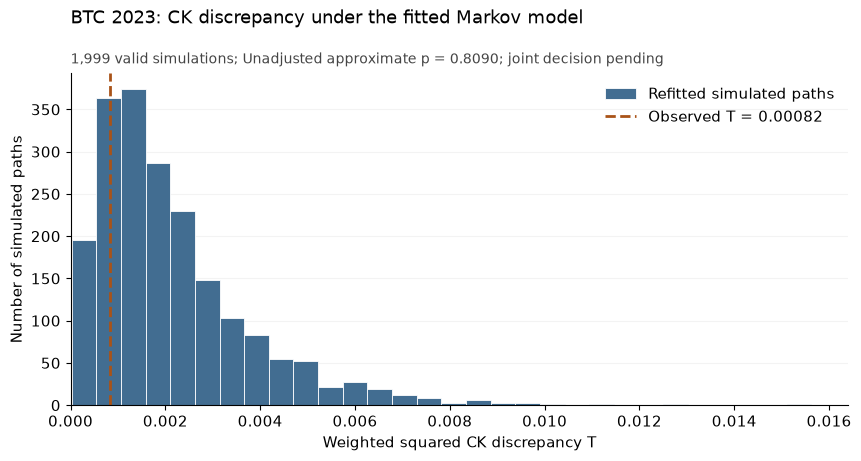

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False}):
    fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
    if len(ck_valid):
        ax.hist(ck_valid, bins=30, color="#426D91", edgecolor="white",
                linewidth=0.6, label="Refitted simulated paths")
    ax.axvline(ck["statistic"], color="#A95318", linestyle="--", linewidth=2,
               label=f"Observed T = {ck['statistic']:.5f}")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Weighted squared CK discrepancy T")
    ax.set_ylabel("Number of simulated paths")
    ax.set_title("BTC 2023: CK discrepancy under the fitted Markov model", loc="left", pad=36)
    p_text = (f"Unadjusted approximate p = {ck_result['p_value']:.4f}"
              if np.isfinite(ck_result["p_value"]) else "p withheld: invalid simulations")
    ax.text(0, 1.03, f"{len(ck_valid):,} valid simulations; {p_text}; joint decision pending",
            transform=ax.transAxes, fontsize=10, color="#454545")
    ax.legend(frameon=False, loc="upper right")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    display(fig)
    plt.close(fig)


### Interpretation and the remaining structural diagnostic

Observed result: T = **0.00082223**. Of 1,999 simulated paths, **1,617**
had discrepancies at least as large; no simulation was invalid. The
unadjusted approximate p-value is **0.8090**. This calculation does not
identify an unusually large five-step discrepancy under the fitted-null
calibration. It does not prove first-order Markov behavior or forecast value.
The joint Holm decision remains pending.

The table reports a **development-stage, unadjusted approximate p-value** for
this one discrepancy. A small value is evidence against the fitted homogeneous
first-order approximation under this calibration; it does not identify whether
the cause is history dependence, time variation, or another misspecification.
A large value does not prove Markovity or forecast usefulness.

The residence-time statistic and its simulation rules are still pending.
The planned joint Holm decision will only be reported once both diagnostics
are available. Complete that structural module before returning to the
forecast-label preparation below. Predictive evaluation is a separate question
and does not require the structural diagnostics to pass.


## 8. Prepare outcome labels for later rolling forecasts

This is the separate prediction workflow. Its labels and maturity filter
are already implemented, but rolling forecasts and scoring remain pending.

For a non-risk origin date \(t\), define

\[
Y_t=\mathbf{1}\{\text{at least one of }S_{t+1},\ldots,S_{t+5}\text{ is }0\}.
\]

The label describes the realized outcome. It is not a probability forecast.
Require all five future daily states to be observed, even if an early hit is
already known. Keep missing labels as missing, not as zero. Starting in state 0
is outside the target population.

`shift(-k)` aligns the state k days ahead with today's row. This forward look
is intentional for constructing outcomes; it must never enter the predictors
at the same date. `target_end_date` is the last required observation date, not
the first-hit date. Before that date, the label is excluded from historical
frequency estimation.


In [21]:
def make_event_labels(states: pd.Series, horizon: int = 5) -> pd.DataFrame:
    """Build realized first-hit labels, retaining unavailable rows explicitly.

    A label requires a non-risk origin and all next h daily states. Its end
    date is always origin + h days, even when the first hit happens earlier.
    Historical estimation must additionally filter target_end_date <= as_of.
    """
    _validate_daily_index(states.index)
    if not states.dropna().isin([0, 1, 2]).all():
        raise ValueError("Observed states must be 0, 1, or 2.")
    if isinstance(horizon, (bool, np.bool_)) or not isinstance(horizon, (int, np.integer)) or horizon < 1:
        raise ValueError("The horizon must be a positive integer.")
    states = states.astype("Int64")

    # Negative shifts align FUTURE outcomes with their origin dates.
    # They are used only for labels, never as inputs to same-date predictions.
    future = pd.DataFrame({
        f"day_{k}": states.shift(-k) for k in range(1, int(horizon) + 1)
    })
    complete_future = future.notna().all(axis=1)
    available = states.isin([1, 2]) & complete_future
    target = pd.Series(pd.NA, index=states.index, dtype="Int64")
    target.loc[available] = future.eq(0).any(axis=1).loc[available].astype(int)

    status = pd.Series("incomplete_future", index=states.index, dtype="string")
    status.loc[states.isna()] = "origin_missing"
    status.loc[states.eq(0).fillna(False)] = "risk_origin"
    status.loc[available] = "available"
    return pd.DataFrame({
        "state": states,
        "target": target,
        "target_end_date": states.index + pd.Timedelta(days=int(horizon)),
        "label_status": status,
    })


In [22]:
labels = make_event_labels(features["state"], horizon=horizon)
display(labels.loc["2023-01-01":"2023-01-05"].style.format({
    "state": "{:.0f}", "target": "{:.0f}", "target_end_date": "{:%Y-%m-%d}",
}, na_rep="unavailable"))


,state,target,target_end_date,label_status
date,,,,
2023-01-01 00:00:00,1,0,2023-01-06,available
2023-01-02 00:00:00,1,0,2023-01-07,available
2023-01-03 00:00:00,1,0,2023-01-08,available
2023-01-04 00:00:00,1,0,2023-01-09,available
2023-01-05 00:00:00,1,0,2023-01-10,available


### Label coverage and the unfinished tail

The following counts account for every 2023 origin date. `available` means
the label can be computed by the end of the development file, not that it was
known on its origin date. The other statuses are mutually exclusive reasons
for exclusion; a risk origin is excluded regardless of future completeness.


In [23]:
labels_2023 = labels.loc[window_start:window_end]
status_order = ["available", "risk_origin", "origin_missing", "incomplete_future"]
label_counts = labels_2023["label_status"].value_counts().reindex(status_order, fill_value=0)
display(label_counts.rename("2023 origin dates").to_frame())


,2023 origin dates
label_status,
available,321
risk_origin,39
origin_missing,0
incomplete_future,5


In [24]:
display(labels_2023.tail(7).style.format({
    "state": "{:.0f}", "target": "{:.0f}", "target_end_date": "{:%Y-%m-%d}",
}, na_rep="unavailable"))


,state,target,target_end_date,label_status
date,,,,
2023-12-25 00:00:00,1,1,2023-12-30,available
2023-12-26 00:00:00,0,unavailable,2023-12-31,risk_origin
2023-12-27 00:00:00,1,unavailable,2024-01-01,incomplete_future
2023-12-28 00:00:00,1,unavailable,2024-01-02,incomplete_future
2023-12-29 00:00:00,1,unavailable,2024-01-03,incomplete_future
2023-12-30 00:00:00,1,unavailable,2024-01-04,incomplete_future
2023-12-31 00:00:00,1,unavailable,2024-01-05,incomplete_future


### Use only labels that have matured by an information cutoff

This illustration uses information available after the January 1, 2023 daily
bar completes. Under the draft rolling rule, the historical origin window is
January 2, 2022 through January 1, 2023. A historical five-day outcome can be
used only if its end date is January 1, 2023 or earlier. Thus its latest
possible origin date is December 27, 2022.

This is an example cutoff, not a permanent parameter-freeze date. In a rolling
forecast, it advances each day. The full-year 2023 matrix above remains a
descriptive calculation and will not be used to score earlier predictions.


In [25]:
as_of = pd.Timestamp("2023-01-01")
history_start = as_of - pd.Timedelta(days=364)
mature_history = labels.loc[
    (labels.index >= history_start)
    & (labels.index <= as_of)
    & labels["target"].notna()
    & (labels["target_end_date"] <= as_of)
]
display(pd.Series({
    "Information cutoff": as_of.date(),
    "Historical origin window starts": history_start.date(),
    "Latest possible mature origin": (as_of - pd.Timedelta(days=horizon)).date(),
    "Available historical labels": len(mature_history),
    "Latest retained origin": mature_history.index.max().date(),
    "Latest retained outcome date": mature_history["target_end_date"].max().date(),
}, name="Maturity filter example").to_frame())


,Maturity filter example
Information cutoff,2023-01-01
Historical origin window starts,2022-01-02
Latest possible mature origin,2022-12-27
Available historical labels,312
Latest retained origin,2022-12-27
Latest retained outcome date,2023-01-01


## Takeaways and next module

The table above provides model-implied probabilities from actual BTC state
transitions. It does not measure forecast accuracy, show improvement over a
baseline, or establish first-order Markov behavior. Section 7 separately reports
an unadjusted approximate CK diagnostic. Uncertainty in the first-passage
probabilities has not been quantified.

Realized five-day labels and their maturity filter are now implemented.
Next, complete the residence-time diagnostic and the joint Holm comparison.
Then add the two historical-frequency baselines and smoothed rolling forecasts,
then score all three on the same eligible development dates. For a forecast
at t, use only data available by t; compare it with the outcome once t+5 has
been observed. The 2023 period is previously used development validation,
not an untouched test set. The residence-time diagnostic remains pending.
Continue extending this notebook instead of creating another notebook for
each learning step.

## Reproducibility checks

The short checks below verify the real-data output and unchanged input file.
Independent path enumeration, threshold boundaries, missing-state handling,
and feature-causality checks are in the synthetic unit tests. Those tests
load only the function-definition cells from this notebook and do not run
its data-loading or analysis cells:

```sh
python -m unittest discover -s tests -p 'test_markov.py' -v
```


In [26]:
assert len(window_states) == 365 and window_states.notna().all()
assert counts.sum() == 364
np.testing.assert_allclose(P.sum(axis=1), 1)
assert hit.between(0, 1).all()
assert np.all(hit.to_numpy() >= endpoint - 1e-12)
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source_sha256
assert label_counts.sum() == 365
assert labels["target"].dropna().isin([0, 1]).all()
assert labels["target"].notna().equals(labels["label_status"].eq("available").astype(bool))
assert labels["target"].iloc[-horizon:].isna().all()
assert (labels["target_end_date"] == labels.index + pd.Timedelta(days=horizon)).all()
assert labels.loc[labels["state"].eq(0).fillna(False), "target"].isna().all()
assert mature_history["target_end_date"].le(as_of).all()
assert (mature_history.index >= history_start).all()
print("Development input, matrix, and event-label checks passed.")
print("Source:", csv_path.relative_to(ROOT))
print("SHA256:", source_sha256)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "pandas:", pd.__version__)

assert ck["counts_lag"].sum() == len(window_states) - horizon
np.testing.assert_allclose(ck["P1"], P)
assert 0 <= ck["statistic"] <= 2 + 1e-12
assert len(ck_result["simulated_statistics"]) == 1999
if ck_result["invalid_simulations"] == 0:
    assert 0 < ck_result["p_value"] <= 1
else:
    assert np.isnan(ck_result["p_value"])
print("CK counts, statistic, and simulation checks passed.")
print("Matplotlib:", plt.matplotlib.__version__)


Development input, matrix, and event-label checks passed.
Source: data/development/BTCUSDT_1d_2020-01_2023-12.csv
SHA256: 64ae4f3a75f61e216c36a7cb41eacaeb645ce3c27b6fd1e4ad3da9c87ef957f5
Python: 3.12.14
NumPy: 2.3.5 pandas: 2.2.3
CK counts, statistic, and simulation checks passed.
Matplotlib: 3.11.2


Execution and presentation: This notebook is saved with executed outputs and
an HTML reading copy. Saved table contents are checked; browser layout has
not been visually inspected.
